# GPT Model Architecture and Text Generation
## Chapter 4: Implementing GPT from Scratch

Assembles a complete GPT-style decoder-only Transformer model from scratch and demonstrates autoregressive text generation.

### Index
1. Imports and Setup
2. GPT Configuration
3. Input Preparation
4. GELU Activation
5. Feed-Forward Network
6. Residual Connection Demonstration
7. Layer Normalization
8. Attention Import
9. Transformer Block
10. GPT Model
11. Model Testing
12. Text Generation
13. Parameter Accounting

## 1. Imports and Setup
Imports libraries required for tensor operations, neural network layers, tokenization, and plotting.

In [1]:
import math
import torch
import torch.nn as nn
import tiktoken
import matplotlib.pyplot as plt

torch.set_printoptions(sci_mode=False)

/home/lakshay/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-lc9lqxfx because there was an issue with the default path (/home/lakshay/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 2. GPT Configuration
Defines the model dimensions and hyperparameters for the GPT architecture.

In [ ]:
GPT_CONFIG = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

## 3. Input Preparation
Tokenizes sample sentences and pads them into a uniform batch tensor.

In [3]:
tokenizer = tiktoken.get_encoding("gpt2")

txt1 = "How are we going to do that???"
txt2 = "I do not know"

tok1 = tokenizer.encode(txt1)
tok2 = tokenizer.encode(txt2)

max_len = max(len(tok1), len(tok2))
pad_token_id = tokenizer.eot_token

# Pad sequences to uniform length
tok1_padded = tok1 + [pad_token_id] * (max_len - len(tok1))
tok2_padded = tok2 + [pad_token_id] * (max_len - len(tok2))

batch = torch.tensor([tok1_padded, tok2_padded])
print("Batch shape:", batch.shape)
print("Batch tensor:")
print(batch)


Batch shape: torch.Size([2, 8])
Batch tensor:
tensor([[ 2437,   389,   356,  1016,   284,   466,   326, 28358],
        [   40,   466,   407,   760, 50256, 50256, 50256, 50256]])


## 4. GELU Activation
Implements the GELU activation function and compares its output against ReLU.

In [4]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1.0 + torch.tanh(
            math.sqrt(2.0 / math.pi) * (x + 0.044715 * torch.pow(x, 3))
        ))

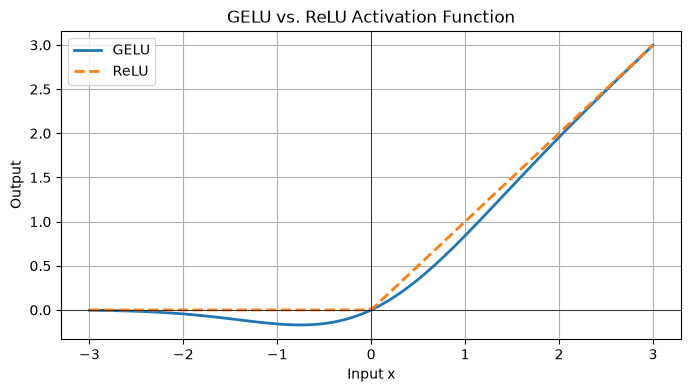

In [5]:
gelu = GELU()
relu = nn.ReLU()

x = torch.linspace(-3, 3, 100)
y_gelu = gelu(x)
y_relu = relu(x)

plt.figure(figsize=(8, 4))
plt.plot(x.numpy(), y_gelu.numpy(), label="GELU", linewidth=2)
plt.plot(x.numpy(), y_relu.numpy(), label="ReLU", linestyle="--", linewidth=2)
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.title("GELU vs. ReLU Activation Function")
plt.xlabel("Input x")
plt.ylabel("Output")
plt.legend()
plt.grid(True)
plt.show()

## 5. Feed-Forward Network
Defines and tests the position-wise feed-forward network used inside Transformer blocks.

In [6]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])
        )

    def forward(self, x):
        return self.layers(x)

In [ ]:
ffn = FeedForward(GPT_CONFIG)
x_test = torch.rand(2, 3, 768)
out_ffn = ffn(x_test)

print("FeedForward input shape: ", x_test.shape)
print("FeedForward output shape:", out_ffn.shape)
assert out_ffn.shape == x_test.shape, "Shape mismatch in FeedForward!"

FeedForward input shape:  torch.Size([2, 3, 768])
FeedForward output shape: torch.Size([2, 3, 768])


## 6. Residual Connection Demonstration
Demonstrates the effect of residual shortcut connections on gradient propagation across deep layers.

In [8]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[i], layer_sizes[i+1]), GELU())
            for i in range(len(layer_sizes) - 1)
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x


def print_gradients(model, x):
    model.zero_grad()
    output = model(x)
    target = torch.tensor([[0.0]])
    loss = nn.MSELoss()(output, target)
    loss.backward()

    for name, param in model.named_parameters():
        if "weight" in name:
            print(f"  {name:20s} | Gradient Mean: {param.grad.abs().mean().item():.6f}")

layer_sizes = [3, 3, 3, 3, 3, 1]
sample_x = torch.randn(1, 3)

print("Without Shortcuts (Gradients diminish in earlier layers):")
torch.manual_seed(123)
model_no_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=False)
print_gradients(model_no_shortcut, sample_x)

print("\nWith Shortcuts (Gradients preserved throughout depth):")
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=True)
print_gradients(model_with_shortcut, sample_x)


Without Shortcuts (Gradients diminish in earlier layers):
  layers.0.0.weight    | Gradient Mean: 0.000238
  layers.1.0.weight    | Gradient Mean: 0.000181
  layers.2.0.weight    | Gradient Mean: 0.000791
  layers.3.0.weight    | Gradient Mean: 0.000712
  layers.4.0.weight    | Gradient Mean: 0.003530

With Shortcuts (Gradients preserved throughout depth):
  layers.0.0.weight    | Gradient Mean: 0.239317
  layers.1.0.weight    | Gradient Mean: 0.217204
  layers.2.0.weight    | Gradient Mean: 0.186789
  layers.3.0.weight    | Gradient Mean: 0.085927
  layers.4.0.weight    | Gradient Mean: 1.184482


## 7. Layer Normalization
Implements and tests feature-wise LayerNorm with learnable scale and shift parameters.

In [9]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

In [ ]:
ln = LayerNorm(emb_dim=768)
x_sample = torch.randn(2, 3, 768)
ln_out = ln(x_sample)

print("LayerNorm input shape: ", x_sample.shape)
print("LayerNorm output shape:", ln_out.shape)
print("Normalized feature mean (approx 0):")
print(ln_out.mean(dim=-1))
print("Normalized feature var (approx 1):")
print(ln_out.var(dim=-1, unbiased=False))
assert ln_out.shape == x_sample.shape, "Shape mismatch in LayerNorm!"


LayerNorm input shape:  torch.Size([2, 3, 768])
LayerNorm output shape: torch.Size([2, 3, 768])
Normalized feature mean (approx 0):
tensor([[-0.0000, -0.0000, -0.0000],
        [-0.0000,  0.0000, -0.0000]], grad_fn=<MeanBackward1>)
Normalized feature var (approx 1):
tensor([[1.0000, 1.0000, 1.0000],
        [1.0000, 1.0000, 1.0000]], grad_fn=<VarBackward0>)


## 8. Attention Import
Loads the causal multi-head attention implementation from the attention module and verifies its output shape.

In [ ]:
import json
import os

def import_class_from_ipynb(nb_path, class_name):
    with open(nb_path, "r", encoding="utf-8") as f:
        nb = json.load(f)
    
    code_blocks = []
    for cell in nb.get("cells", []):
        if cell.get("cell_type") == "code":
            src = "".join(cell.get("source", []))
            if "batch_size = 2" in src:  
                continue
            code_blocks.append(src)
            
    exec_scope = {"torch": torch, "nn": nn, "math": math}
    exec("\n".join(code_blocks), exec_scope)
    return exec_scope[class_name]

candidates = [
    os.path.abspath("../Attention/multihead_self_attention.ipynb"),
    os.path.abspath("src/buildinglargelanguagemodel/Attention/multihead_self_attention.ipynb"),
    "/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/Attention/multihead_self_attention.ipynb"
]
nb_mha_path = next(p for p in candidates if os.path.exists(p))
CausalMultiHeadSelfAttention = import_class_from_ipynb(nb_mha_path, "CausalMultiHeadSelfAttention")

print("Successfully imported CausalMultiHeadSelfAttention from:", nb_mha_path)


Successfully imported CausalMultiHeadSelfAttention from: /home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/Attention/multihead_self_attention.ipynb


In [ ]:
torch.manual_seed(123)
att = CausalMultiHeadSelfAttention(
    d_model=GPT_CONFIG["emb_dim"],
    num_heads=GPT_CONFIG["n_heads"],
    context_length=GPT_CONFIG["context_length"],
    dropout=GPT_CONFIG["drop_rate"],
    qkv_bias=GPT_CONFIG["qkv_bias"]
)

x_att_test = torch.randn(2, 8, 768)
out_att = att(x_att_test)

print("Attention input shape: ", x_att_test.shape)
print("Attention output shape:", out_att.shape)
assert out_att.shape == x_att_test.shape, "Attention output shape mismatch!"
assert not torch.isnan(out_att).any(), "Attention produced NaN values!"

Attention input shape:  torch.Size([2, 8, 768])
Attention output shape: torch.Size([2, 8, 768])


## 9. Transformer Block
Combines causal attention and the feed-forward network with Pre-LayerNorm, dropout, and residual connections.

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = CausalMultiHeadSelfAttention(
            d_model=cfg["emb_dim"],
            num_heads=cfg["n_heads"],
            context_length=cfg["context_length"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        return x

In [ ]:
block = TransformerBlock(GPT_CONFIG)
out_block = block(x_test)

print("TransformerBlock input shape: ", x_test.shape)
print("TransformerBlock output shape:", out_block.shape)
assert out_block.shape == x_test.shape, "TransformerBlock output shape mismatch!"
assert not torch.equal(out_block, x_test), "TransformerBlock is behaving like an identity function!"

TransformerBlock input shape:  torch.Size([2, 3, 768])
TransformerBlock output shape: torch.Size([2, 3, 768])


## 10. GPT Model
Assembles token embeddings, positional embeddings, Transformer blocks, final normalization, and the output vocabulary projection.

In [ ]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
        )

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        if seq_len > self.cfg["context_length"]:
            raise ValueError(
                f"Sequence length {seq_len} exceeds context length {self.cfg['context_length']}"
            )

        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

## 11. Model Testing
Initializes the GPT model and verifies the output shape of the logits across a batch forward pass.

In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG)
model.eval()

with torch.no_grad():
    logits = model(batch)

print("Input batch shape :", batch.shape)
print("Output logits shape:", logits.shape)
assert logits.shape == (batch.shape[0], batch.shape[1], GPT_CONFIG["vocab_size"]), "Logits shape mismatch!"
print("Sample logits (first token, first 5 vocab entries):")
print(logits[0, 0, :5])


Input batch shape : torch.Size([2, 8])
Output logits shape: torch.Size([2, 8, 50257])
Sample logits (first token, first 5 vocab entries):
tensor([-0.6802, -0.1727, -0.1432,  0.4647, -0.5943])


## 12. Text Generation
Implements greedy autoregressive generation to sample tokens iteratively from a prompt.

In [ ]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)

        logits = logits[:, -1, :]
        probas = torch.softmax(logits, dim=-1)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)

        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [ ]:
start_context = "Every effort moves you"
encoded_prompt = torch.tensor(tokenizer.encode(start_context)).unsqueeze(0)

print("Prompt text :", start_context)
print("Prompt tokens:", encoded_prompt)

token_ids = generate_text_simple(
    model=model,
    idx=encoded_prompt,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"]
)

generated_text = tokenizer.decode(token_ids.squeeze(0).tolist())
print("\nGenerated tokens shape:", token_ids.shape)
print("Generated text:")
print(generated_text)


Prompt text : Every effort moves you
Prompt tokens: tensor([[6109, 3626, 6100,  345]])



Generated tokens shape: torch.Size([1, 10])
Generated text:
Every effort moves you Aeiman Byeswickattributeometer


## 13. Parameter Accounting
Calculates total model parameters and counts the parameters contained within the Transformer blocks.

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total model parameters: {total_params:,}")

total_params_without_emb = sum(p.numel() for p in model.trf_blocks.parameters())
print(f"Total parameters in Transformer blocks: {total_params_without_emb:,}")

Total model parameters: 163,009,536
Total parameters in Transformer blocks: 85,026,816
